# EuroSAT Land-Use Classification
This project compares the performance of a *Random Forest* and a small *CNN* model in classification of satelite images. I used 1500 images per class were used. Before training a random forest, the images were processed for features. Feature extraction included HSV colour histogram and Canny edge density resulting in a total of 513 features 

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import cv2
import torch
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os

root = '/kaggle/input'
for dirpath, dirnames, filenames in os.walk(root):
    depth = dirpath[len(root):].count(os.sep)
    if depth <= 4:
        print(dirpath, '| subfolders:', len(dirnames), '| files:', len(filenames))
    if depth >= 4:
        dirnames[:] = []   # Stop going deeper

import torch
print("GPU available:", torch.cuda.is_available())
import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input | subfolders: 1 | files: 0
/kaggle/input/datasets | subfolders: 1 | files: 0
/kaggle/input/datasets/waseemalastal | subfolders: 1 | files: 0
/kaggle/input/datasets/waseemalastal/eurosat-rgb-dataset | subfolders: 1 | files: 0
/kaggle/input/datasets/waseemalastal/eurosat-rgb-dataset/EuroSAT_RGB | subfolders: 10 | files: 0
GPU available: True


## Count and View Samples
In the following cell, we'll explore each directory (each folder is a class) extracting the number of instances in it plus visualizing a sample from each class.

['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
AnnualCrop             3000
Forest                 3000
HerbaceousVegetation   3000
Highway                2500
Industrial             2500
Pasture                2000
PermanentCrop          2500
Residential            3000
River                  2500
SeaLake                3000


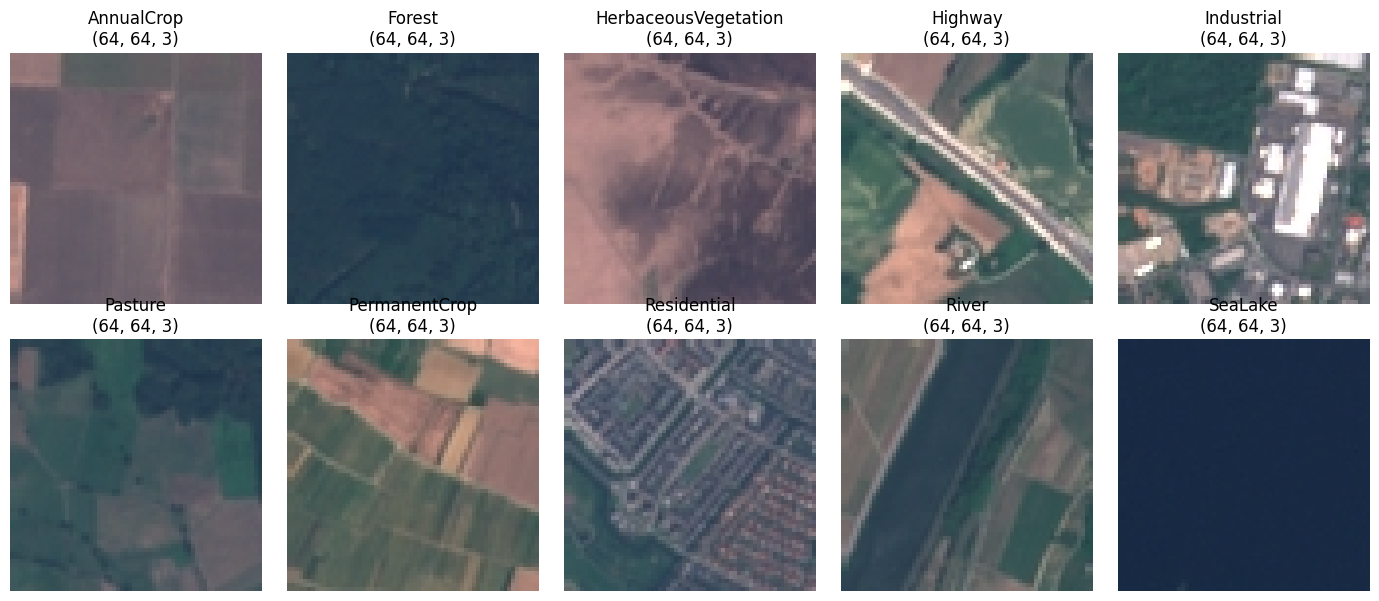

In [ ]:
import glob
import matplotlib.pyplot as plt

# Path to the EuroSAT RGB dataset on Kaggle
DATA_DIR = '/kaggle/input/datasets/waseemalastal/eurosat-rgb-dataset/EuroSAT_RGB'

# Each folder is one class, so the folder names are the class names
classes = sorted(os.listdir(DATA_DIR))
print(classes)

# Count the images in each class to check the dataset is balanced
for c in classes:
    n = len(glob.glob(os.path.join(DATA_DIR, c, '*'))) # '*' includes all the files in the directory regardless of file name
    print(f'{c:22s} {n}') # 22s is a formatting struction, each class name occupies 22 characters

# Show one image from each class in a 2x5 grid
fig, axes = plt.subplots(2, 5, figsize=(14, 6)) # 2 rows and 5 columns
for ax, c in zip(axes.ravel(), classes): # axes.ravel() flattens the axes 2d grid to match with the classes list
    path = sorted(glob.glob(os.path.join(DATA_DIR, c, '*')))[0] # chooses the very first instance in the directory
    img = cv2.imread(path)                       # OpenCV loads images as BGR
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # Convert to RGB, because matplotlib needs RGB
    ax.imshow(img)
    ax.set_title(f'{c}\n{img.shape}')            # Show the class name and the image shape
    ax.axis('off')
plt.tight_layout()
plt.show()

## Load the Data and Split into train and test
Loading only 1500 samples per class to boost the process. 

In [ ]:
from tqdm import tqdm # loads a progress bar tool (shows if something is stuck), used to avoid failed attempts while loading
from sklearn.model_selection import train_test_split

# Limit images per class so loading stays fast, set to None to load everything
MAX_PER_CLASS = 1500

# Load images into X and labels into y, with a progress bar for each class
X, y = [], []
for label, c in enumerate(classes): # Label is the index that enumerate returns
    paths = sorted(glob.glob(os.path.join(DATA_DIR, c, '*')))
    if MAX_PER_CLASS:
        paths = paths[:MAX_PER_CLASS] # Only path to the first 1500
    for path in tqdm(paths, desc=c):
        img = cv2.imread(path)     # Keep BGR, because OpenCV functions expect it
        X.append(img)
        y.append(label)

X = np.array(X, dtype=np.uint8)
y = np.array(y)
print('X shape:', X.shape, '| y shape:', y.shape)

# Save the arrays so I never have to load the images again
np.save('/kaggle/working/X.npy', X)
np.save('/kaggle/working/y.npy', y)

# 80% train and 20% test, stratify keeps the class proportions the same
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42 # startify=y keeps the same class proportions in the train and test
)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Class balance in test set:', np.bincount(y_test)) # Counts how many times each class appears

SeaLake: 100%|██████████| 1500/1500 [01:32<00:00, 16.16it/s]


X shape: (15000, 64, 64, 3) | y shape: (15000,)
Train: (12000, 64, 64, 3) | Test: (3000, 64, 64, 3)
Class balance in test set: [300 300 300 300 300 300 300 300 300 300]


## Feature Extraction and Normalization
Next, we will extract features out of each instance, so that we pass the features into the training instead of the images themselves. Features include histogram on hsv channels and edge detection using Canny. After this particular cell, we have 513 features for each image. 512 features from hsv channel and one from edge detection. Since we have divided each hsv channel into 8 bins, we may have 512 **combination** of *hues*, *saturations* and *values* which tells us what how many of the pixels fall into each combination class. After detecting the edges in the same input, we take the ratio of the edges to the entire pixel count. Therefore, we have 513 features.

In [ ]:
from tqdm import tqdm

def extract_features(img):
    # Convert to HSV, because colour information is easier to separate there than in BGR
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    # 3D colour histogram with 8 bins per channel (8x8x8 = 512 values)
    hist = cv2.calcHist([hsv], [0, 1, 2], None, [8, 8, 8], [0, 180, 0, 256, 0, 256]) # using all three hsv channels, no mask, each channel into 8 bins, channel ranges
    hist = (hist / hist.sum()).flatten()      # Normalize so the values sum to 1

    # Edge density: the fraction of pixels that Canny marks as edges
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray, 100, 200)
    edge_density = edges.mean() / 255

    # Join everything into one feature vector (513 values)
    return np.append(hist, edge_density)

# Extract the features for the train and test sets
F_train = np.array([extract_features(img) for img in tqdm(X_train, desc='train')])
F_test = np.array([extract_features(img) for img in tqdm(X_test, desc='test')])
print('Feature shapes:', F_train.shape, F_test.shape)

test: 100%|██████████| 3000/3000 [00:00<00:00, 4883.48it/s]


Feature shapes: (12000, 513) (3000, 513)


## Training a Random Forest
Here we'll train a *random forest* on the features we just extracted. A random forest is constructed from many trees where each tree votes for a specific class and the majority wins. This architecture consists of 200 trees ran on all CPU core, for faster performance, with a random state seed of 42 that guarantees the same results in multiple runs. Finally, four evaluation metrics were taken into consideration, precision, recall, f1-score, and accuracy.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Random Forest on the OpenCV features with 200 trees
# n_jobs=-1 uses all CPU cores, random_state=42 keeps the result the same every run
rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
rf.fit(F_train, y_train)

# Predict on the test set and check the accuracy
rf_pred = rf.predict(F_test)
rf_acc = accuracy_score(y_test, rf_pred)
print(f'Random Forest accuracy: {rf_acc:.4f}')
print(classification_report(y_test, rf_pred, target_names=classes))

Random Forest accuracy: 0.8153
                      precision    recall  f1-score   support

          AnnualCrop       0.86      0.88      0.87       300
              Forest       0.87      0.88      0.88       300
HerbaceousVegetation       0.85      0.89      0.87       300
             Highway       0.69      0.55      0.61       300
          Industrial       0.88      0.95      0.91       300
             Pasture       0.78      0.86      0.82       300
       PermanentCrop       0.81      0.75      0.78       300
         Residential       0.83      0.90      0.86       300
               River       0.66      0.67      0.66       300
             SeaLake       0.91      0.82      0.86       300

            accuracy                           0.82      3000
           macro avg       0.81      0.82      0.81      3000
        weighted avg       0.81      0.82      0.81      3000



## Convert features into Tensors
In this section we'll need to convert the BGR color space to RGB and normalize the data by bringing the pixel values from a range of 0 to 255 to the range of 0 to 1. Also PyTorch expects the channels dimension first so using permute(), we tune the dimensionality.

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Convert BGR to RGB, scale to 0-1, and change the shape to (N, 3, 64, 64) for PyTorch
def to_tensor(X):
    X = X[..., ::-1].copy()                      # BGR to RGB, the ... preserves the first three dimensionalities and ::-1 reverses the channels
    X = torch.from_numpy(X).float() / 255.0      # NumPy array to tensor and scale pixels to 0-1
    return X.permute(0, 3, 1, 2)                 # (N, H, W, C) to (N, C, H, W)

Xt_train, Xt_test = to_tensor(X_train), to_tensor(X_test)
yt_train, yt_test = torch.from_numpy(y_train).long(), torch.from_numpy(y_test).long()

# Put the data in loaders, batches of 64, shuffle only the training data
train_loader = DataLoader(TensorDataset(Xt_train, yt_train), batch_size=64, shuffle=True)
test_loader = DataLoader(TensorDataset(Xt_test, yt_test), batch_size=256)
print(Xt_train.shape, Xt_test.shape)

torch.Size([12000, 3, 64, 64]) torch.Size([3000, 3, 64, 64])


## Define CNN architecture

In [ ]:
# Small CNN: 3 blocks of conv + batch norm + ReLU + max pool, then a classifier
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10): # n_classes: the number of output classes
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU(),
                nn.MaxPool2d(2),
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.pool = nn.AdaptiveAvgPool2d(1)      # Average each feature map to one number
        self.fc = nn.Linear(128, n_classes)

    def forward(self, x):
        x = self.pool(self.features(x)).flatten(1)
        return self.fc(x)

device = 'cpu'                                   # No GPU, so I use the CPU
model = SmallCNN().to(device)
print(sum(p.numel() for p in model.parameters()), 'parameters')

94986 parameters


## Normalize, Hold Out a Validation set, and Load the Data
First, we must choose wether to use *CPU* or *GPU*. Then, normalize the data by calculating the *mean* and *standard deviation* for each instance. Later, load the data with similar proportions of classes in each set and suffling before passing it into the network.

In [ ]:
from sklearn.model_selection import train_test_split

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using:', device)

# Normalize each channel with the training mean and std
mean = Xt_train.mean(dim=(0, 2, 3), keepdim=True) # Claculates the mean for each channel seperately
std = Xt_train.std(dim=(0, 2, 3), keepdim=True)  # Calculates the standard deviation for each channel seperately
Xn_train = (Xt_train - mean) / std # Normalizing the sets
Xn_test = (Xt_test - mean) / std

# Hold out 10% of the training data as validation, so I never choose epochs using the test set
idx_tr, idx_val = train_test_split(
    np.arange(len(Xn_train)), test_size=0.1, stratify=y_train, random_state=42 # Returns the indexes of instances for each set, keeping the proportions of each class equal
)
train_loader = DataLoader(TensorDataset(Xn_train[idx_tr], yt_train[idx_tr]), batch_size=64, shuffle=True) # Loading data witha suffle to avoid passing the input in same sequences
val_loader = DataLoader(TensorDataset(Xn_train[idx_val], yt_train[idx_val]), batch_size=256)
test_loader = DataLoader(TensorDataset(Xn_test, yt_test), batch_size=256)
print(len(idx_tr), 'train |', len(idx_val), 'val |', len(Xn_test), 'test')

Using: cuda
10800 train | 1200 val | 3000 test


## Data Augmentation, Defining Training Loop, and Model Fitting


In [ ]:
import time

# Random flips per image, satellite images look the same flipped
def augment(xb):
    fh = torch.rand(xb.size(0), device=xb.device) < 0.5 # Assigns a random number to each image, if num < 0.5 True
    xb = torch.where(fh[:, None, None, None], xb.flip(3), xb) # Check if the image is True, choose the flipped version else the original
    fv = torch.rand(xb.size(0), device=xb.device) < 0.5 # Same for vertical flip
    return torch.where(fv[:, None, None, None], xb.flip(2), xb)

# Return the predictions of the model for a loader
def predict(loader):
    model.eval()
    out = []
    with torch.no_grad(): # We don't need gradient descent while  predicting
        for xb, _ in loader:
            out.append(model(xb.to(device)).argmax(1).cpu()) # argmax() returns the class which got the highest value in prediction
    return torch.cat(out).numpy() # returns the result of different batches

model = SmallCNN().to(device) # Define model                   
EPOCHS = 20 # 20 iterations on the entire dataset, each iteration is one epoch
criterion = nn.CrossEntropyLoss() # Calculating the error
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4) # Parameter update
# OneCycleLR raises the learning rate at first, then lowers it slowly, which keeps training stable
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=3e-3, epochs=EPOCHS, steps_per_epoch=len(train_loader) # max_lr is the maximum learning rate value, steps_per_epoch is the batch size
)

best_val, best_state = 0, None
for epoch in range(EPOCHS):
    start = time.time()
    model.train()
    for xb, yb in train_loader: # Iterate over batches, xb: images, yb: labels
        xb, yb = augment(xb.to(device)), yb.to(device) # Augment data and move to device
        optimizer.zero_grad() # Turn the former value of gradients to zero, we'll calculate the new gradients
        loss = criterion(model(xb), yb) # Compute loss
        loss.backward() # Compute gradient
        optimizer.step() # update model weights or parameters
        scheduler.step() # update learning rate

    # Validation accuracy decides which epoch is the best, not the test set
    val_acc = accuracy_score(y_train[idx_val], predict(val_loader))
    if val_acc > best_val:
        best_val = val_acc
        best_state = {k: v.clone() for k, v in model.state_dict().items()} # cloning best weights so that next epoch doesn't affect them
    print(f'Epoch {epoch+1}/{EPOCHS} | val acc {val_acc:.4f} | {time.time()-start:.0f}s')

# Load the best model by validation and test it only once
model.load_state_dict(best_state)
cnn_pred = predict(test_loader)
cnn_acc = accuracy_score(y_test, cnn_pred)
print(f'Final CNN test accuracy: {cnn_acc:.4f}')

Epoch 1/20 | val acc 0.6675 | 3s
Epoch 2/20 | val acc 0.7033 | 2s
Epoch 3/20 | val acc 0.7425 | 2s
Epoch 4/20 | val acc 0.7483 | 2s
Epoch 5/20 | val acc 0.7183 | 2s
Epoch 6/20 | val acc 0.7767 | 2s
Epoch 7/20 | val acc 0.7317 | 2s
Epoch 8/20 | val acc 0.8375 | 2s
Epoch 9/20 | val acc 0.8258 | 2s
Epoch 10/20 | val acc 0.8000 | 2s
Epoch 11/20 | val acc 0.8675 | 2s
Epoch 12/20 | val acc 0.9142 | 2s
Epoch 13/20 | val acc 0.9017 | 2s
Epoch 14/20 | val acc 0.9208 | 2s
Epoch 15/20 | val acc 0.9108 | 2s
Epoch 16/20 | val acc 0.9325 | 2s
Epoch 17/20 | val acc 0.9317 | 2s
Epoch 18/20 | val acc 0.9433 | 2s
Epoch 19/20 | val acc 0.9442 | 2s
Epoch 20/20 | val acc 0.9408 | 2s
Final CNN test accuracy: 0.9460


## Confusion Matrix
Here we have compared the predictions with actual labels and seperated the incorrect predictions by class. The vertical side shows the actual classes and tracking each class across the table to a different class shows how many of the predictions were falsly grouped under second class. 
For instance, 88% of the *AnnualCrops* in random forest model were predicted correctly and about 2% were classified as *Pasture*. One interesting point is that the random forest performed very poorly on Highway predictions and only 55% of the predictions were correct.

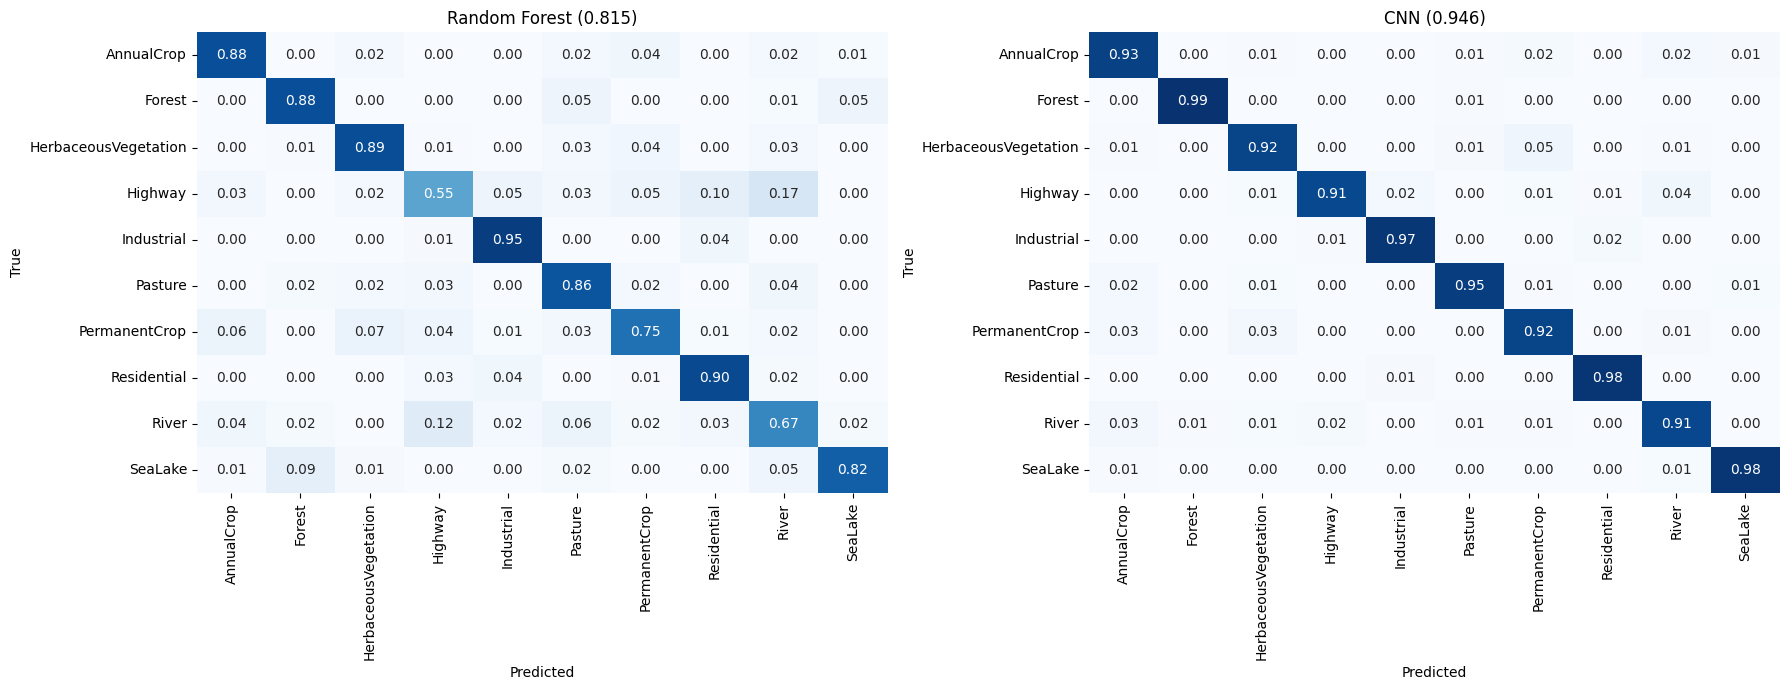

In [13]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Confusion matrix for each model, normalized by row so each row shows the share of that true class
cm_rf = confusion_matrix(y_test, rf_pred, normalize='true')
cm_cnn = confusion_matrix(y_test, cnn_pred, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, cm, title in zip(axes, [cm_rf, cm_cnn],
                         [f'Random Forest ({rf_acc:.3f})', f'CNN ({cnn_acc:.3f})']):
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1,
                xticklabels=classes, yticklabels=classes, ax=ax, cbar=False)
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
plt.tight_layout()
plt.show()

## F1 Score
In the last part of model performance evaluation, we'll use F1 score which gives us a harmonic evaluation of *precision* and *recall*. Precision calculates the percentage of the images that actually belonged to a certain class. For instance, out of all the instances predicted as River, how many were actually river images?

Recall however, tells us how many of one class were correctly predicted. Consider the river example once more. Recall answers the question of out of all the actual River images, how many were identified as River?

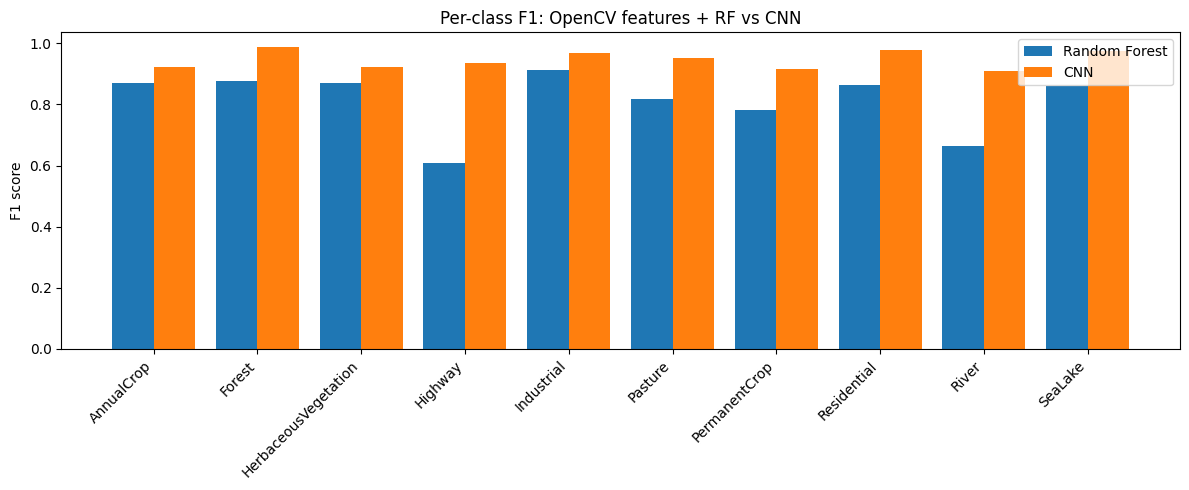

HerbaceousVegetation -> PermanentCrop: 15 images
Highway -> River: 12 images
PermanentCrop -> HerbaceousVegetation: 10 images


In [14]:
from sklearn.metrics import f1_score

# F1 score of each class for both models
f1_rf = f1_score(y_test, rf_pred, average=None)
f1_cnn = f1_score(y_test, cnn_pred, average=None)

# Bar chart to compare the two models class by class
x = np.arange(len(classes))
plt.figure(figsize=(12, 5))
plt.bar(x - 0.2, f1_rf, 0.4, label='Random Forest')
plt.bar(x + 0.2, f1_cnn, 0.4, label='CNN')
plt.xticks(x, classes, rotation=45, ha='right')
plt.ylabel('F1 score')
plt.title('Per-class F1: OpenCV features + RF vs CNN')
plt.legend()
plt.tight_layout()
plt.show()

# Find the 3 most confused pairs of the CNN (true class -> predicted class)
cm_counts = confusion_matrix(y_test, cnn_pred)
np.fill_diagonal(cm_counts, 0)                    # Ignore the correct predictions
top = np.dstack(np.unravel_index(np.argsort(cm_counts.ravel())[::-1], cm_counts.shape))[0][:3]
for t, p in top:
    print(f'{classes[t]} -> {classes[p]}: {cm_counts[t, p]} images')

In [15]:
# F1 of each class for both models, side by side
for c, a, b in zip(classes, f1_rf, f1_cnn):
    print(f'{c:22s} RF {a:.2f} | CNN {b:.2f}')

AnnualCrop             RF 0.87 | CNN 0.92
Forest                 RF 0.88 | CNN 0.99
HerbaceousVegetation   RF 0.87 | CNN 0.92
Highway                RF 0.61 | CNN 0.94
Industrial             RF 0.91 | CNN 0.97
Pasture                RF 0.82 | CNN 0.95
PermanentCrop          RF 0.78 | CNN 0.92
Residential            RF 0.86 | CNN 0.98
River                  RF 0.66 | CNN 0.91
SeaLake                RF 0.86 | CNN 0.97
